# Import Environment variables

In [1]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.ipynb

Found bucket: id=rw-migration-aou-rw-f7a4d148, bucketName=rw-migration-aou-rw-f7a4d148
-> Assigned migration variables (ID: rw-migration-aou-rw-f7a4d148)
Found bucket: id=temporary-workspace-bucket, bucketName=temporary-workspace-bucket-wb-perky-cabbage-8342
Found bucket: id=workspace-bucket, bucketName=workspace-bucket-wb-perky-cabbage-8342
✅ Successfully identified latest dataset: wb-silky-artichoke-2408.C2024Q3R9

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-perky-cabbage-8342
WORKSPACE_BUCKET: gs://workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_TEMP_BUCKET: gs://temporary-workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9
bucket_aou_tutorial: NOT FOUND
bucket_id_aou_tutorial: NOT FOUND
bucket_migrated: gs://rw-migration-aou-rw-f7a4d148
bucket_id_migrated: rw-migration-aou-rw-f7a4d148

✅ Saved to /home/jupyter/.bashrc
C2024Q3R9 BQ_DATASET
Multi-trait-GWAS-in-admixed-populations GIT_REPO
prep_C2024Q3R9 BQ_DATASET
rw-migration-aou-rw-f7a4d148 GC

In [2]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.ipynb

WORKSPACE_CDR = wb-silky-artichoke-2408.C2024Q3R9
WORKSPACE_BUCKET = gs://workspace-bucket-wb-perky-cabbage-8342
GOOGLE_PROJECT = wb-perky-cabbage-8342
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.R
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.sas


# Import library

In [3]:
%load_ext autoreload
%autoreload 2
    
import os
import subprocess
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

import my_function as mf

# Data's import

## Importation des données issues du notebook `54_Breast_Cancer_WITHIN_5Y_DataSelectionAndFiltering`

## Clinical data

In [4]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_bc_ko_at_inclusion_223k_nb_BC_WITHIN_5Y_GeneticAncestry_biopsy_FamilyHistory_LastSelection.tsv"

df = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)
df

VersionError: Detected incompatible Protobuf Gencode/Runtime versions when loading google/iam/v1/iam_policy.proto: gencode 6.33.5 runtime 6.32.0. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.

In [ ]:
df.drop(columns=['gender','date_of_birth','ethnicity','self_reported_category','time_category','delay_years',
                 'first_any_biopsy_date','days_inclusion_to_biopsy', 'days_biopsy_to_cancer',
                 'first_survey_date', 'last_survey_date','days_last_survey_to_first_survey', 'days_inclusion_to_first_survey',
                 'days_inclusion_to_last_survey', 'days_has_bc_to_first_survey','days_has_bc_to_last_survey',
                 'date_1_of_biopsy_19081_19086', 'date_2_of_biopsy_19081_19086', 'date_3_of_biopsy_19081_19086',
                 'has_biopsy_19081_19086',
                 'date_1_of_biopsy_19100_19103', 'date_2_of_biopsy_19100_19103', 'date_3_of_biopsy_19100_19103',
                 'has_biopsy_19100_19103',
                 'date_1_of_biopsy_19120_19125_19126', 'date_2_of_biopsy_19120_19125_19126', 'date_3_of_biopsy_19120_19125_19126',
                 'has_biopsy_19120_19125_19126',
                 'Daughter', 'Mother', 'Sibling',
                 'statut_parente'], inplace=True)

In [ ]:
df.columns

# Selection of African women 

In [ ]:
df[(df['race_us_bcsc_detail'] == 'afr_rye') & (df['afr_rye'] > 0.8)].value_counts('has_bc')

In [ ]:
df_afr = df[df['race_us_bcsc_detail'] == 'afr_rye'].copy()

In [ ]:
df_afr

## BCSC v2 Model

### Calcul du score BCSC

#### Script appliquant l'équation de régression logistique du modèle BCSC V2

In [ ]:
def calculate_bcsc_v2_risk_5years(row):
    """Calcule le risque absolu à 5 ans de cancer du sein invasif (Modèle BCSC v2)

    sans donnée de densité (densité imputée/neutre).
    """
    age = row["age_at_inclusion"]
    race = row["race_us_bcsc"]  # 1: White, 2: Black, 3: Asian, 8: Other/Mixed
    fam_hist = row[
        "breast_cancer_family_history_first_degree"
    ]  # 0: Non, 1: Oui (1 relative), 2: Oui (>=2 relatives)
    biopsy = row["biopsy_result"]  # 0: Non, 1: Oui (biopsie bénigne)

    # 1. Odds Ratios (Log-Odds) du modèle BCSC v2 (Tice et al. 2015)
    # Relative Risk (RR) par rapport à la catégorie de référence

    # Antecedents familiaux
    beta_fam = {0: 0.0, 1: 0.47, 2: 0.88}.get(fam_hist, 0.0)

    # Antécédent de biopsie bénigne
    beta_biopsy = 0.36 if biopsy == 1 else 0.0

    # Ethnicité (Ajustement du risque de base relative)
    beta_race = {
        1: 0.0,  # White (Référence)
        2: -0.12,  # Black
        3: -0.22,  # Asian
        8: -0.05,  # Other / Mixed
    }.get(race, 0.0)

    # Densité inconnue (Poids neutre / Risque relatif moyen = 1.0 -> beta = 0.0)
    beta_density = 0.0

    # 2. Somme des effets relatifs (Log Relative Risk)
    log_rr = beta_fam + beta_biopsy + beta_race + beta_density
    rr = np.exp(log_rr)

    # 3. Taux d'incidence de base (Baseline Hazard à 5 ans selon l'âge)
    # Issu des tables d'incidence de référence BCSC / SEER (Tice et al.)
    if 40 <= age < 45:
        base_rate_5yr = 0.0051
    elif 45 <= age < 50:
        base_rate_5yr = 0.0084
    elif 50 <= age < 55:
        base_rate_5yr = 0.0118
    elif 55 <= age < 60:
        base_rate_5yr = 0.0142
    elif 60 <= age < 65:
        base_rate_5yr = 0.0163
    elif 65 <= age < 70:
        base_rate_5yr = 0.0178
    elif 70 <= age < 75:
        base_rate_5yr = 0.0185
    else:
        base_rate_5yr = 0.0100  # Hors bornes

    # 4. Calcul du risque absolu à 5 ans
    # Risk = 1 - exp(- Baseline_Hazard * RR)
    risk_5yr = 1.0 - np.exp(-base_rate_5yr * rr)

    return risk_5yr

### Application du modèle BCSC

In [ ]:
# Application sur ton DataFrame
df_afr["score_bcscRisk"] = (df_afr.apply(calculate_bcsc_v2_risk_5years, axis=1))

In [ ]:
df_afr["score_bcscRisk"].plot.hist(bins=30)

## Mammorisk Model

### Import Mammorisk®

In [ ]:
pip install pycryptodome

In [ ]:
import getpass
import io
from Crypto.Cipher import AES
from Crypto.Protocol.KDF import PBKDF2

In [ ]:
def load_encrypted_csv(enc_file_path, password):
    with open(enc_file_path, "rb") as f:
        salt = f.read(16)
        nonce = f.read(16)
        tag = f.read(16)
        ciphertext = f.read()

    # Dériver la même clé
    key = PBKDF2(password, salt, dkLen=32, count=100000)

    # Déchiffrer
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    decrypted_data = cipher.decrypt_and_verify(ciphertext, tag)

    # Charger directement dans Pandas via RAM
    return pd.read_csv(io.BytesIO(decrypted_data))

In [ ]:
# Usage
my_encrypt_file= "Datas/mammorisk_encrypted_remi.enc"

password = getpass.getpass("Entrez le mot de passe MammoRisk : ")
df_mammorisk = load_encrypted_csv(my_encrypt_file, password)
print("✅ Fichier chargé en mémoire RAM ! Shape :", df_mammorisk.shape)

### Application du modèle Mammorisk®

In [23]:
df_afr.rename(columns={"biopsy_result": "biopsy"}, inplace=True)

In [24]:
# 1. Vérification/Harmonisation des noms de colonnes dans All of Us
# On s'assure que les colonnes de jointure ont des types identiques (int)
join_keys = [
    "age_category",
    "race_us_bcsc",
    "breast_cancer_family_history_first_degree",
    "biopsy",
]

# 2. Application de la jointure (merge) pour récupérer le score
df_Mammorisk = (df_afr.merge(df_mammorisk, on=join_keys, how="left"))

In [25]:
df_Mammorisk.rename(columns={"score_knn_v27_weighted_average_breast_density": "score_mammorisk"}, inplace=True)

In [26]:
# 4. Vérification de l'application
missing_scores = df_Mammorisk["score_mammorisk"].isna().sum()
print(f"Nombre d'individus avec un score MammoRisk attribué : {len(df_Mammorisk) - missing_scores}")
print(f"Nombre de scores manquants (échec de jointure) : {missing_scores}")

Nombre d'individus avec un score MammoRisk attribué : 26116
Nombre de scores manquants (échec de jointure) : 0


<Axes: ylabel='Frequency'>

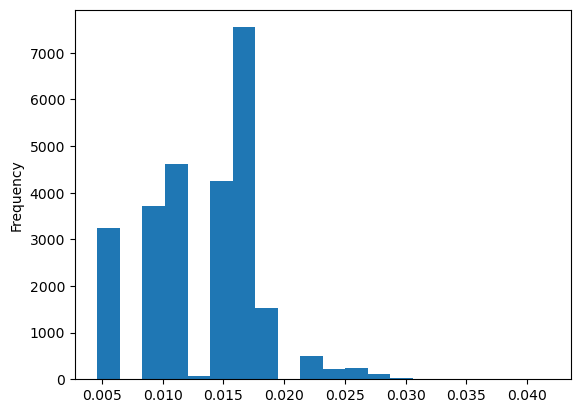

In [27]:
df_Mammorisk["score_mammorisk"].plot.hist(bins=20)

## PRS 298, 305 et 311 recalibrate

In [31]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_all_prs_298_305_311.csv"

df_prs = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

In [36]:
df_prs.columns

Index(['index', 'prs_298', 'risk_ratio_298', 'num_snps_with_genotypes_298',
       'num_snps_total_298', 'prs_305', 'risk_ratio_305',
       'num_snps_with_genotypes_305', 'num_snps_total_305', 'prs_311',
       'risk_ratio_311', 'num_snps_with_genotypes_311', 'num_snps_total_311'],
      dtype='object')

In [42]:
df_prs_afr = df_afr.merge(df_prs, left_on='person_id', right_on='index', how='left')
df_prs_afr

,person_id,inclusion_date,first_breast_cancer_date,delay_days,age_at_inclusion,has_bc,eur_rye,eas_rye,amr_rye,afr_rye,...,num_snps_with_genotypes_298,num_snps_total_298,prs_305,risk_ratio_305,num_snps_with_genotypes_305,num_snps_total_305,prs_311,risk_ratio_311,num_snps_with_genotypes_311,num_snps_total_311
0,1700611,2019-09-17,NaN,NaN,70.255989,0,0.091868,0.000000,0.0,0.848348,...,291.0,298.0,0.229474,1.072436,298.0,305.0,0.278546,1.113760,303.0,311.0
1,3095344,2018-07-30,NaN,NaN,57.122519,0,0.149522,0.004112,0.0,0.788366,...,295.0,298.0,-0.173435,0.777275,302.0,305.0,-0.221363,0.748905,307.0,311.0
2,5876855,2022-11-03,NaN,NaN,61.385352,0,0.048679,0.000000,0.0,0.886872,...,295.0,298.0,0.363527,1.193668,302.0,305.0,0.518085,1.347048,308.0,311.0
3,2646710,2019-08-23,NaN,NaN,55.186858,0,0.229365,0.003343,0.0,0.738013,...,295.0,298.0,0.517120,1.349508,302.0,305.0,0.676192,1.527205,307.0,311.0
4,1197462,2019-11-07,NaN,NaN,55.394935,0,0.079360,0.000000,0.0,0.851251,...,294.0,298.0,0.618058,1.462844,301.0,305.0,0.625131,1.466532,306.0,311.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26111,2898673,2018-11-15,NaN,NaN,56.418891,0,0.454550,0.007665,0.0,0.527306,...,297.0,298.0,0.142940,1.000799,304.0,305.0,0.112607,0.976286,307.0,311.0
26112,4923391,2022-02-07,NaN,NaN,46.650240,0,0.387291,0.000000,0.0,0.524171,...,293.0,298.0,0.295977,1.130957,300.0,305.0,0.278536,1.113752,306.0,311.0
26113,1257233,2020-01-21,NaN,NaN,62.600958,0,0.272983,0.000000,0.0,0.698327,...,295.0,298.0,0.935618,1.885303,302.0,305.0,0.943577,1.888380,308.0,311.0
26114,2816958,2019-01-22,NaN,NaN,46.603696,0,0.144538,0.000000,0.0,0.820630,...,294.0,298.0,0.055707,0.933425,301.0,305.0,0.060965,0.937069,307.0,311.0


# result of BCSC v2 model

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import auc, roc_curve


def bootstrap_auc(y_true_ser, y_scores_ser, n_bootstraps=1000, rng_seed=42):
    """Calcule l'intervalle de confiance à 95% de l'AUC-ROC par bootstrap."""
    bootstrapped_scores = []
    rng = np.random.RandomState(rng_seed)
    y_true_arr = (
        y_true_ser.values.ravel()
        if hasattr(y_true_ser, "values")
        else np.asarray(y_true_ser).ravel()
    )
    y_scores_arr = (
        y_scores_ser.values.ravel()
        if hasattr(y_scores_ser, "values")
        else np.asarray(y_scores_ser).ravel()
    )

    n_samples = len(y_scores_arr)
    for _ in range(n_bootstraps):
        indices = rng.randint(0, n_samples, n_samples)
        if len(np.unique(y_true_arr[indices])) < 2:
            continue
        score = auc(*roc_curve(y_true_arr[indices], y_scores_arr[indices])[:2])
        bootstrapped_scores.append(score)

    sorted_scores = np.sort(bootstrapped_scores)
    return (
        sorted_scores[int(0.025 * len(sorted_scores))],
        sorted_scores[int(0.975 * len(sorted_scores))],
    )


def evaluate_and_plot_model(
    df_data,
    score_col,
    test_ids=None,
    target_col="has_bc",
    alpha_val=0.0,
    id_col="person_id",
    model_name="Modèle",
    quantiles=None,
    labels=None,
    ref_quantile_idx=2,
    figsize=(16, 6),
):
    """Évalue et trace discrimination (ROC) et calibration (Incidence/OR).

    Fonctionne sur un sous-ensemble (test_ids) ou sur l'ensemble complet de la cohorte si test_ids=None.
    """
    if quantiles is None:
        quantiles = [0.0, 0.20, 0.40, 0.60, 0.80, 1.0]
    if labels is None:
        labels = [
            "Q1 (<20%)",
            "Q2 (20-40%)",
            "Q3 (40-60%)",
            "Q4 (60-80%)",
            "Q5 (>80%)",
        ]

    # 1. Sélection : sous-ensemble test OU cohorte complète
    if test_ids is not None:
        ids_to_match = (
            test_ids.values.ravel()
            if hasattr(test_ids, "values")
            else np.asarray(test_ids).ravel()
        )
        df_cohort = df_data[df_data[id_col].isin(ids_to_match)].copy()
        cohort_tag = "Test"
    else:
        df_cohort = df_data.copy()
        cohort_tag = "Cohorte complète"

    df_eval = (
        df_cohort.dropna(subset=[target_col, score_col])
        .reset_index(drop=True)
        .copy()
    )

    y_true = df_eval[target_col]
    p_brut = df_eval[score_col]

    # 2. Application de l'éventuelle recalibration d'intercept
    if alpha_val != 0.0:
        p_clipped = np.clip(p_brut, 1e-6, 1.0 - 1e-6)
        logit_p = np.log(p_clipped / (1.0 - p_clipped))
        logit_p_recalib = logit_p + alpha_val
        p_eval = 1.0 / (1.0 + np.exp(-logit_p_recalib))
    else:
        p_eval = p_brut

    recalib_col_name = (
        f"{score_col}_eval" if alpha_val == 0.0 else f"{score_col}_recalib"
    )
    df_eval[recalib_col_name] = p_eval

    # 3. Métriques ROC et AUC
    fpr, tpr, _ = roc_curve(y_true, p_eval)
    roc_auc = auc(fpr, tpr)
    ci_lower, ci_upper = bootstrap_auc(y_true, p_eval)

    # 4. Métriques O/E (Calibration globale)
    observed_cases = int(y_true.sum())
    expected_brut = float(p_brut.sum())
    expected_recalib = float(p_eval.sum())

    oe_brut = observed_cases / expected_brut if expected_brut > 0 else np.nan
    oe_recalib = (
        observed_cases / expected_recalib if expected_recalib > 0 else np.nan
    )

    # 5. Découpage en Quantiles & Calculs par groupe
    df_eval["risk_group"] = pd.qcut(
        df_eval[recalib_col_name],
        q=quantiles,
        labels=labels,
        duplicates="drop",
    )

    # A. Incidence réelle (%)
    incidence = df_eval.groupby("risk_group", observed=False)[target_col].agg(
        ["mean", "count"]
    )
    incidence["pct"] = incidence["mean"] * 100
    incidence = incidence.reindex(labels)

    # B. Risque moyen prédit (%)
    pred_risk = df_eval.groupby("risk_group", observed=False)[
        recalib_col_name
    ].mean()
    pred_risk_pct = (pred_risk * 100).reindex(labels)

    # C. Odds Ratios par régression logistique
    dummies = pd.get_dummies(df_eval["risk_group"], drop_first=False)
    ref_col = labels[ref_quantile_idx]
    if ref_col not in dummies.columns:
        ref_col = dummies.columns[len(dummies.columns) // 2]

    X = dummies.drop(columns=[ref_col]).astype(int)
    X = sm.add_constant(X)

    logit_mod = sm.Logit(y_true, X).fit(disp=False)
    conf = logit_mod.conf_int()

    or_df = pd.DataFrame(
        {
            "OR": np.exp(logit_mod.params),
            "lower": np.exp(conf[0]),
            "upper": np.exp(conf[1]),
        }
    )
    or_df.loc["const"] = [1.0, 1.0, 1.0]
    or_df.index = [c if c != "const" else ref_col for c in or_df.index]
    or_df = or_df.reindex(labels)

    # 6. Tracé de la Figure
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # --- Subplot 1 : ROC & Cartouche O/E ---
    axes[0].plot(
        fpr,
        tpr,
        color="darkorange",
        lw=2,
        label=f"{model_name} (AUC = {roc_auc:.3f} [{ci_lower:.3f}-{ci_upper:.3f}])",
    )
    axes[0].plot(
        [0, 1],
        [0, 1],
        color="navy",
        lw=1.5,
        linestyle="--",
        label="Hasard (AUC = 0.50)",
    )
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel("1 - Spécificité", fontsize=10)
    axes[0].set_ylabel("Sensibilité", fontsize=10)
    axes[0].set_title(
        f"Courbe ROC - {model_name} ({cohort_tag} N={len(df_eval)})",
        fontsize=11,
        fontweight="bold",
    )
    axes[0].legend(loc="lower right")
    axes[0].grid(True, linestyle=":", alpha=0.6)

    # Cartouche dynamique
    if alpha_val != 0.0:
        calib_text = (
            f"• Cas attendus (E brut) : {expected_brut:.1f}\n"
            rf"• $\mathbf{{Ratio\ O/E\ brut\ :}}$ {oe_brut:.3f}"
            "\n\n"
            rf"$\mathbf{{Recalibré\ (\alpha = {alpha_val:.4f}):}}$"
            "\n"
            f"• Cas attendus (E recalib) : {expected_recalib:.1f}\n"
            rf"• $\mathbf{{Ratio\ O/E\ recalib\ :}}$ {oe_recalib:.3f}"
        )
    else:
        calib_text = (
            f"• Cas attendus (E) : {expected_brut:.1f}\n"
            rf"• $\mathbf{{Ratio\ O/E\ :}}$ {oe_brut:.3f}"
        )

    text_str = (
        rf"$\mathbf{{Calibration\ globale\ ({cohort_tag}):}}$"
        "\n"
        rf"• $\mathbf{{Cas\ observés\ (O)\ :}}$ {observed_cases}"
        "\n\n"
        f"{calib_text}"
    )

    axes[0].text(
        0.04,
        0.96,
        text_str,
        transform=axes[0].transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9,
        ),
    )

    # --- Subplot 2 : Barres d'Incidence/Risque Prédit + OR ---
    x_pos = np.arange(len(labels))

    axes[1].bar(
        x_pos - 0.15,
        incidence["pct"],
        width=0.3,
        alpha=0.6,
        color="skyblue",
        edgecolor="navy",
        label="Incidence réelle (%)",
    )

    axes[1].bar(
        x_pos + 0.15,
        pred_risk_pct,
        width=0.3,
        alpha=0.6,
        color="orange",
        edgecolor="darkorange",
        label="Risque prédit moyen (%)",
    )

    axes[1].set_xlabel("Quantiles de risque", fontsize=10)
    axes[1].set_ylabel(
        "Pourcentage (%)", fontsize=10, color="navy", fontweight="bold"
    )
    axes[1].tick_params(axis="y", labelcolor="navy")
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(labels, rotation=30)
    axes[1].grid(True, linestyle=":", alpha=0.4)

    ax2 = axes[1].twinx()
    valid_or = or_df.dropna(subset=["OR"])
    valid_x = [labels.index(idx) for idx in valid_or.index if idx in labels]

    line_or = ax2.errorbar(
        valid_x,
        valid_or["OR"],
        yerr=[
            valid_or["OR"] - valid_or["lower"],
            valid_or["upper"] - valid_or["OR"],
        ],
        fmt="o-",
        color="darkred",
        ecolor="crimson",
        elinewidth=1.8,
        capsize=4,
        markersize=6,
        label="Odds Ratio (IC 95%)",
    )

    ax2.axhline(1.0, color="gray", linestyle="--", alpha=0.7)
    ax2.set_ylabel(
        f"Odds Ratio (OR) vs Quantile Médian ({ref_col})",
        fontsize=10,
        color="darkred",
        fontweight="bold",
    )
    ax2.tick_params(axis="y", labelcolor="darkred")

    lines_1, labels_1 = axes[1].get_legend_handles_labels()
    axes[1].legend(
        lines_1 + [line_or],
        labels_1 + ["Odds Ratio (IC 95%)"],
        loc="upper left",
        frameon=True,
        fontsize=8.5,
    )

    axes[1].set_title(
        f"Incidence, Risque prédit et Odds Ratios ({model_name})",
        fontsize=11,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

    metrics = {
        "AUC": roc_auc,
        "AUC_CI": (ci_lower, ci_upper),
        "OE_brut": oe_brut,
        "OE_recalib": oe_recalib,
        "alpha": alpha_val,
        "N_total": len(df_eval),
    }

    return metrics, df_eval

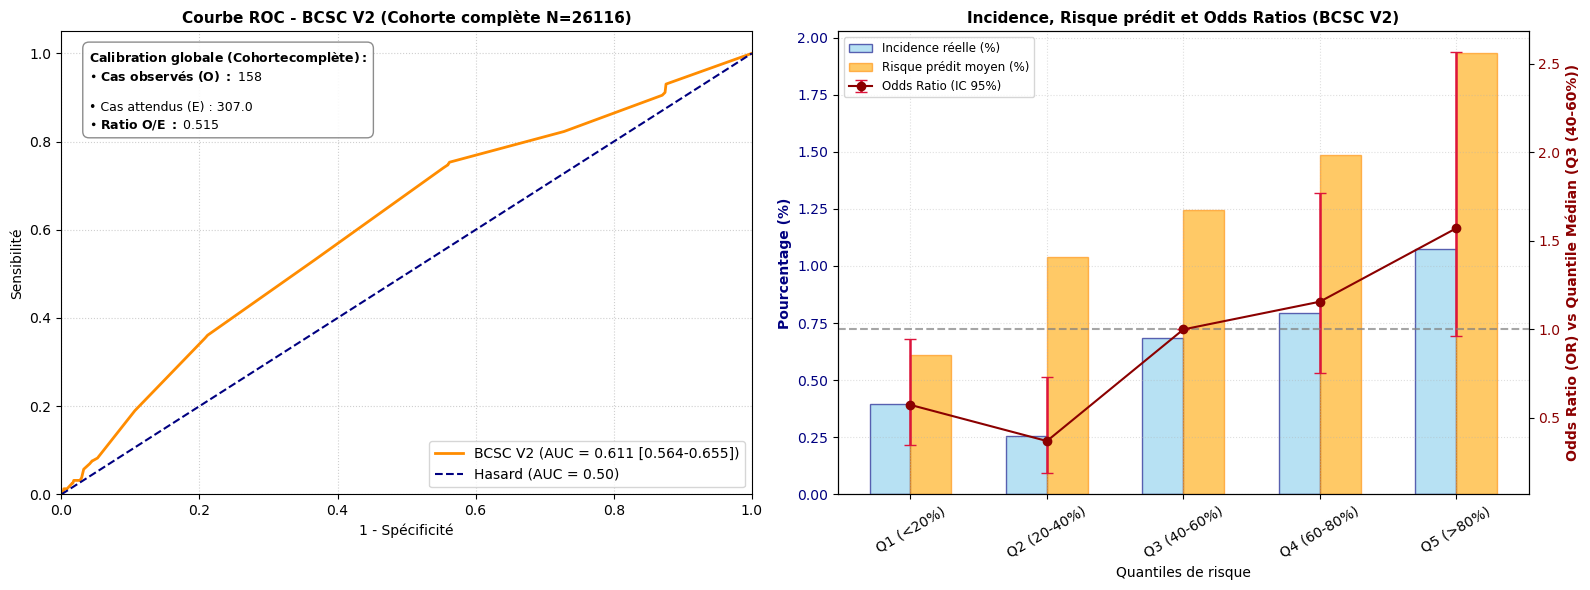

In [15]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_afr,
    score_col="score_bcscRisk",  # ou score_bcscRisk, prs_311, etc.
    model_name="BCSC V2 (Africaines)",
    target_col="has_bc",
)

# result of Mammorisk model

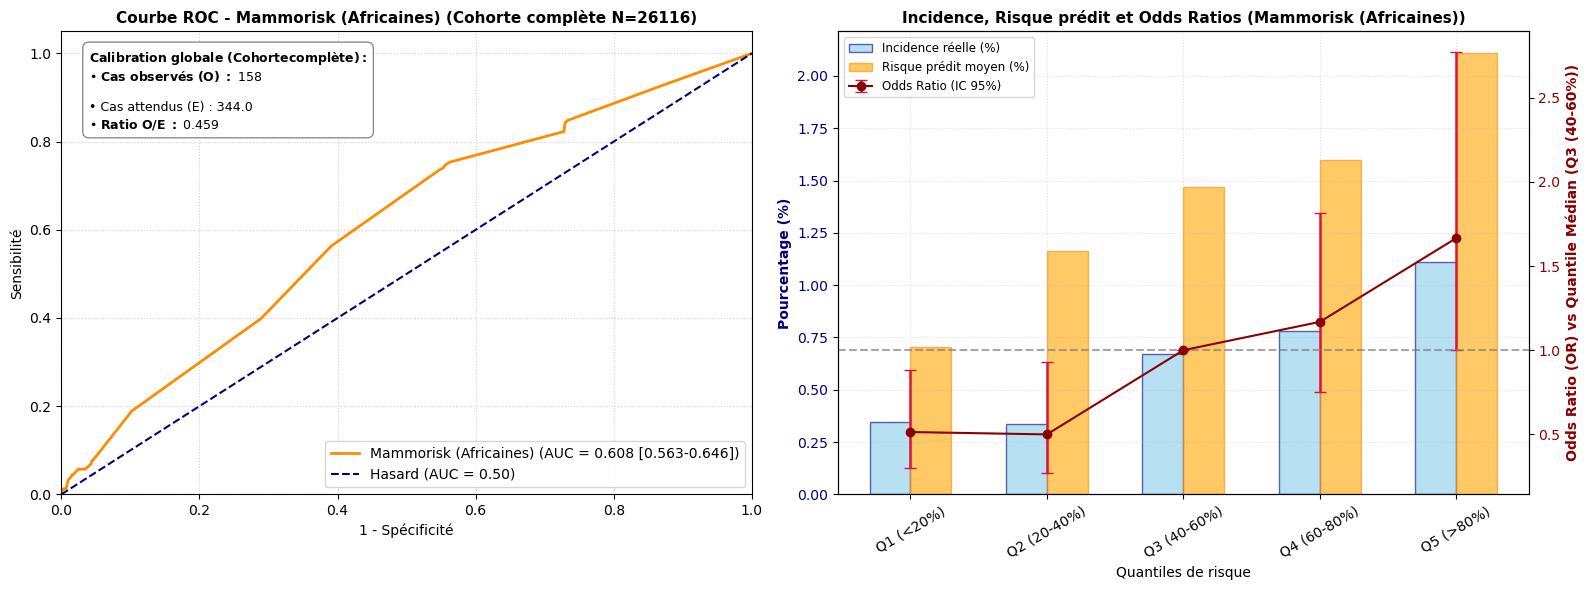

In [29]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_Mammorisk,
    score_col="score_mammorisk",  # ou score_bcscRisk, prs_311, etc.
    model_name="Mammorisk (Africaines)",
    target_col="has_bc",
)

# result of PRS298 model

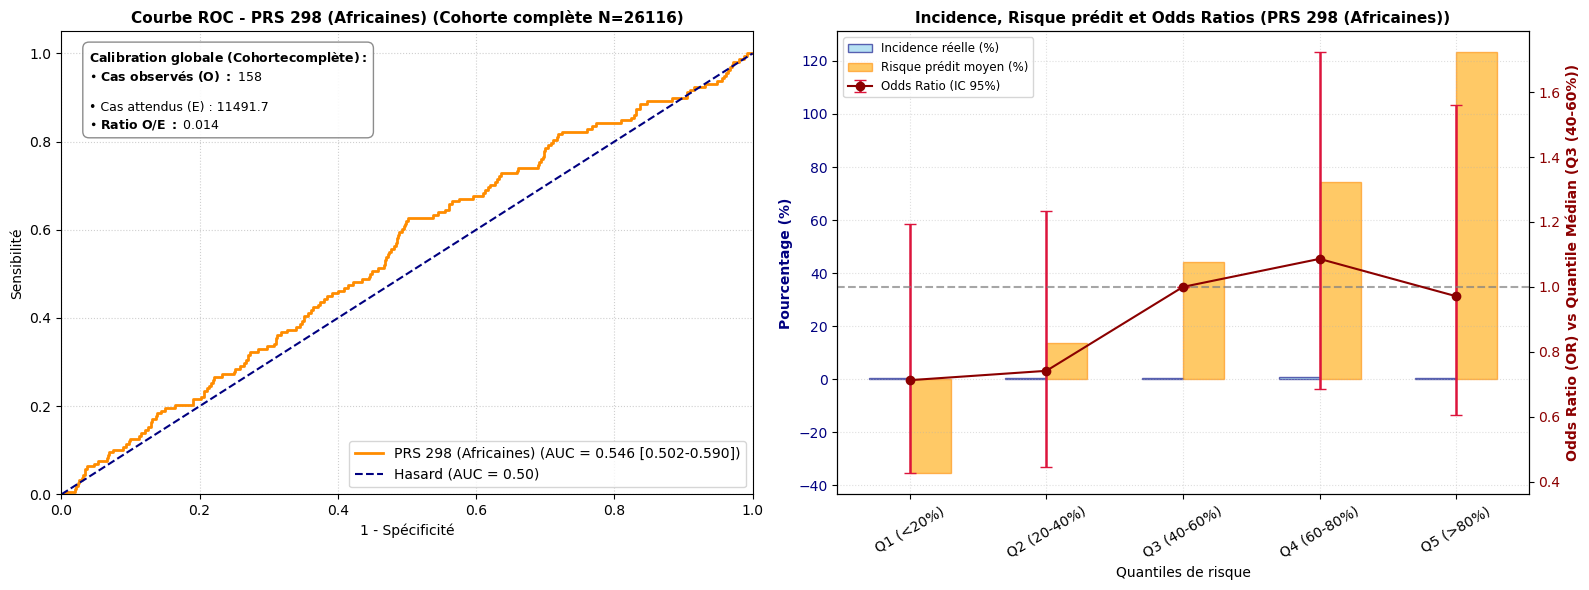

In [47]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_prs_afr,
    score_col="prs_298",  # ou score_bcscRisk, prs_311, etc.
    model_name="PRS 298 (Africaines)",
    target_col="has_bc",
)

# result of PRS305 model

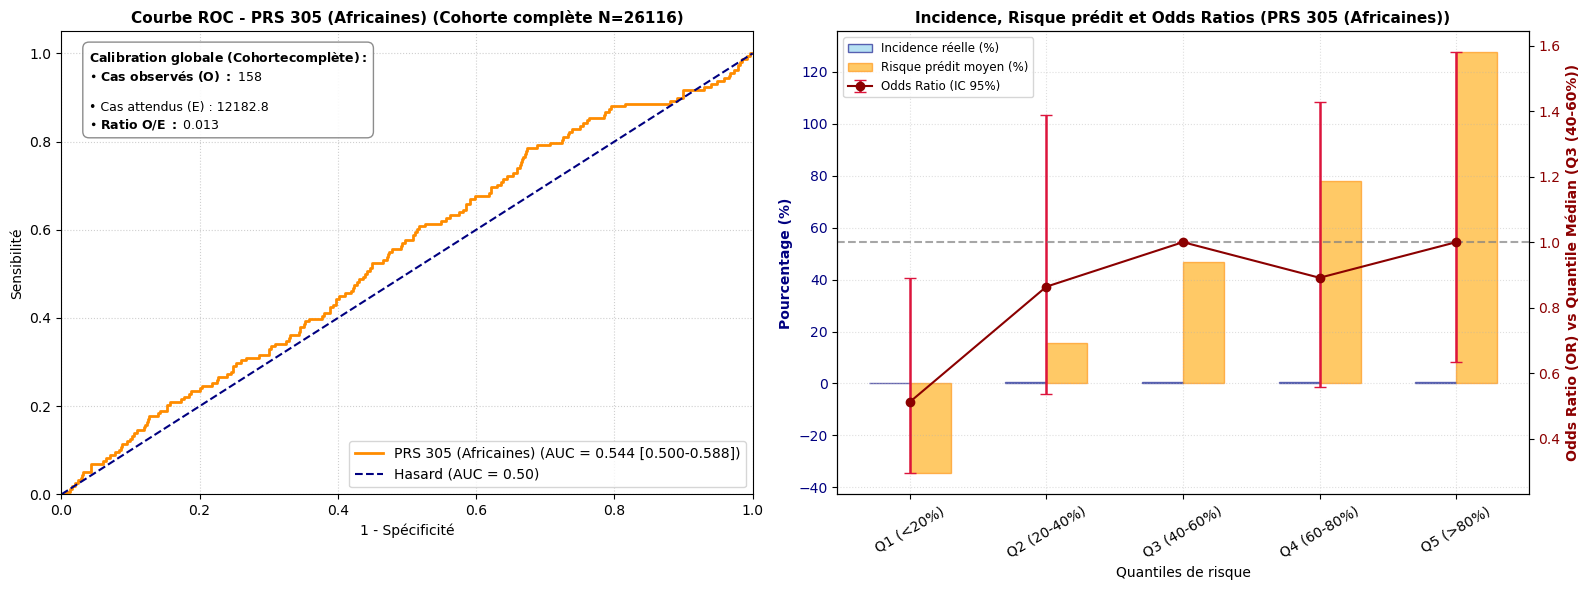

In [48]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_prs_afr,
    score_col="prs_305",  # ou score_bcscRisk, prs_311, etc.
    model_name="PRS 305 (Africaines)",
    target_col="has_bc",
)

# result of PRS311 model

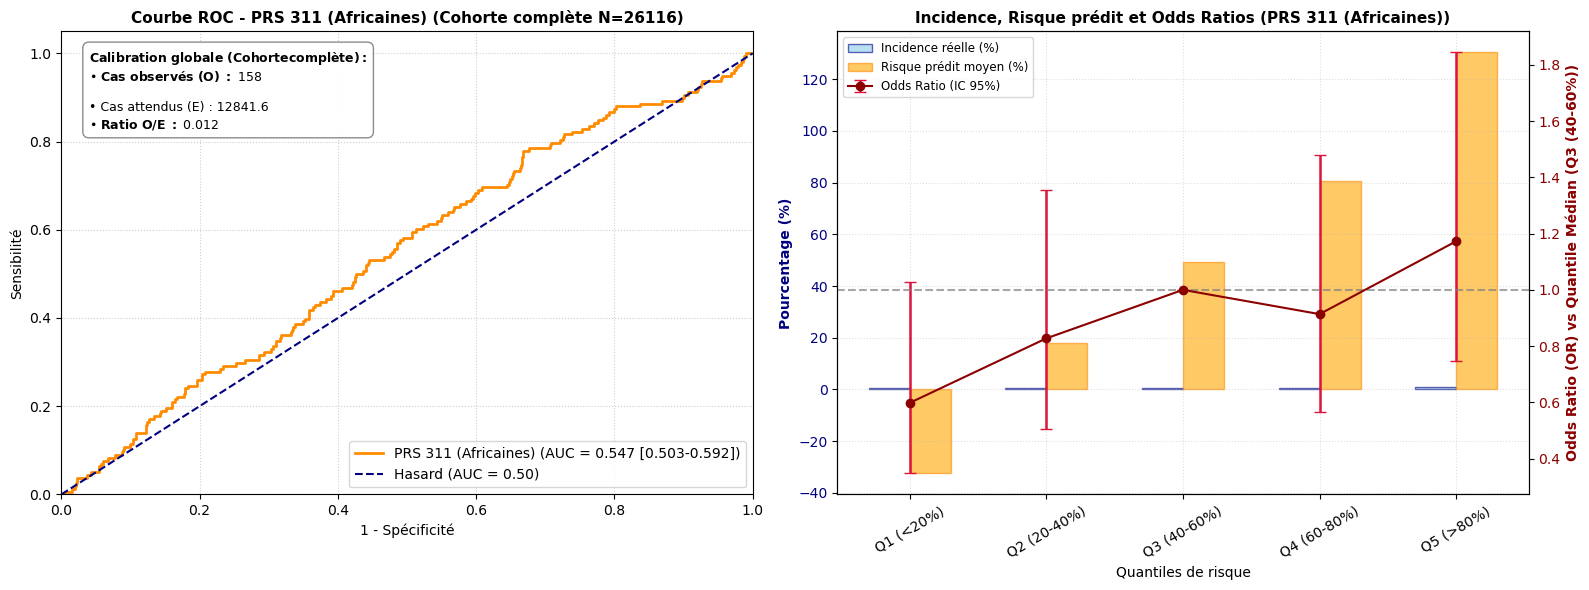

In [49]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_prs_afr,
    score_col="prs_311",  # ou score_bcscRisk, prs_311, etc.
    model_name="PRS 311 (Africaines)",
    target_col="has_bc",
)

# Combine Clinical and PRS model

In [68]:
import numpy as np
import pandas as pd


def combine_clinical_and_prs(
    df_data,
    beta_prs=0.2789,  # Coefficient beta de la régression logistique du PRS-311
    bcsc_col="score_bcscRisk_recalib",
    mammo_col="score_mammorisk_recalib",
    prs_z_col="prs_311_z",
):
    """Combine les modèles cliniques (BCSC et Mammorisk) avec le PRS-311

    selon l'approche bayésienne/logistique à effets additifs (Élie Rassy et al.).
    """
    df_out = df_data.copy()

    # Protection contre log(0) ou log(1)
    eps = 1e-7
    p_bcsc = np.clip(df_out[bcsc_col], eps, 1 - eps)
    p_mammo = np.clip(df_out[mammo_col], eps, 1 - eps)

    # 1. Conversion des probabilités cliniques en log-odds (logit)
    logit_bcsc = np.log(p_bcsc / (1 - p_bcsc))
    logit_mammo = np.log(p_mammo / (1 - p_mammo))

    # 2. Addition du composant génétique (beta * PRS_z)
    genetic_component = beta_prs * df_out[prs_z_col]

    logit_bcsc_prs = logit_bcsc + genetic_component
    logit_mammo_prs = logit_mammo + genetic_component

    # 3. Reconversion inverse en probabilités absolues combinées
    df_out["prob_bcsc_prs311"] = 1.0 / (1.0 + np.exp(-logit_bcsc_prs))
    df_out["prob_mammorisk_prs311"] = 1.0 / (1.0 + np.exp(-logit_mammo_prs))

    return df_out

In [69]:
df_combine_models = df_Mammorisk.merge(df_prs_afr[['person_id','prs_298','prs_305','prs_311']], on='person_id', how='left')

In [77]:
# Application directe sur ton DataFrame df_scores
df_scores = combine_clinical_and_prs(
    df_data=df_combine_models,
    beta_prs=0,  # Remplace par la valeur exacte de beta de ton PRS-311 si différente
    bcsc_col="score_bcscRisk",
    mammo_col="score_mammorisk",
    prs_z_col="prs_311",
)

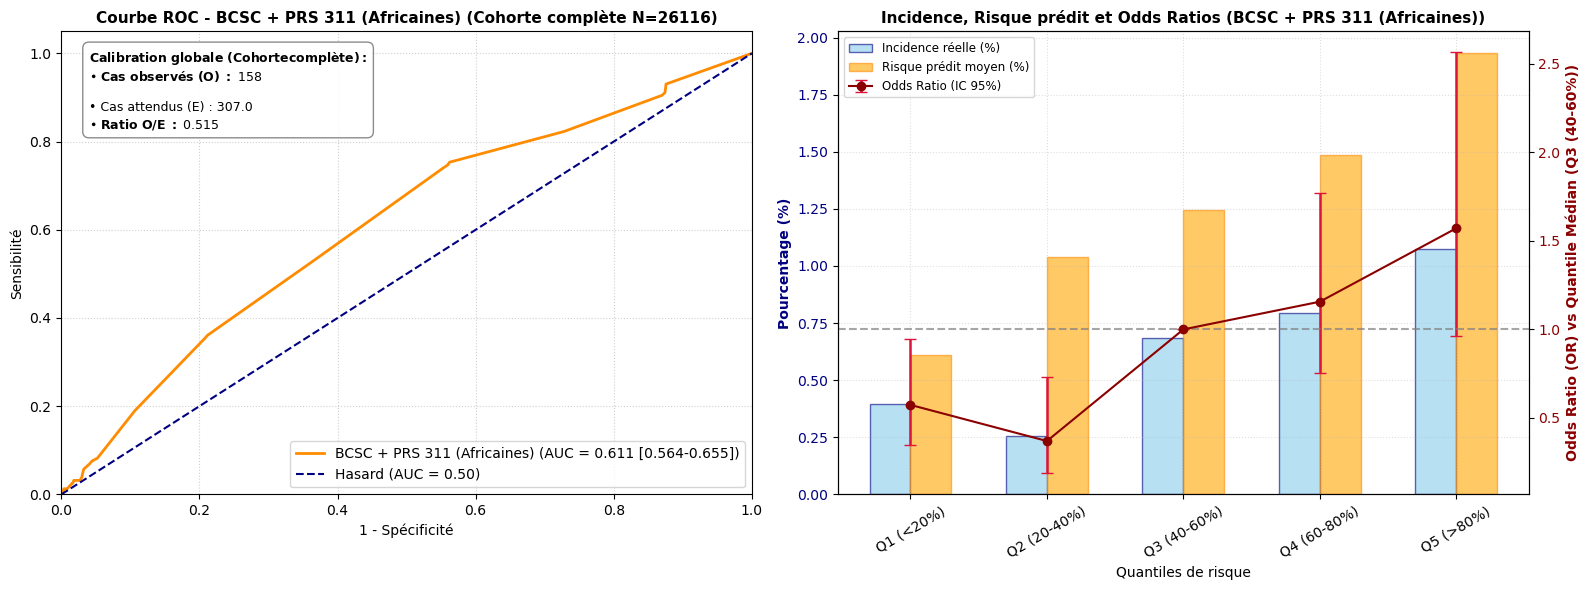

In [80]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_scores,
    score_col="prob_bcsc_prs311",  # ou score_bcscRisk, prs_311, etc.
    model_name="BCSC + PRS 311 (Africaines)",
    target_col="has_bc",
)

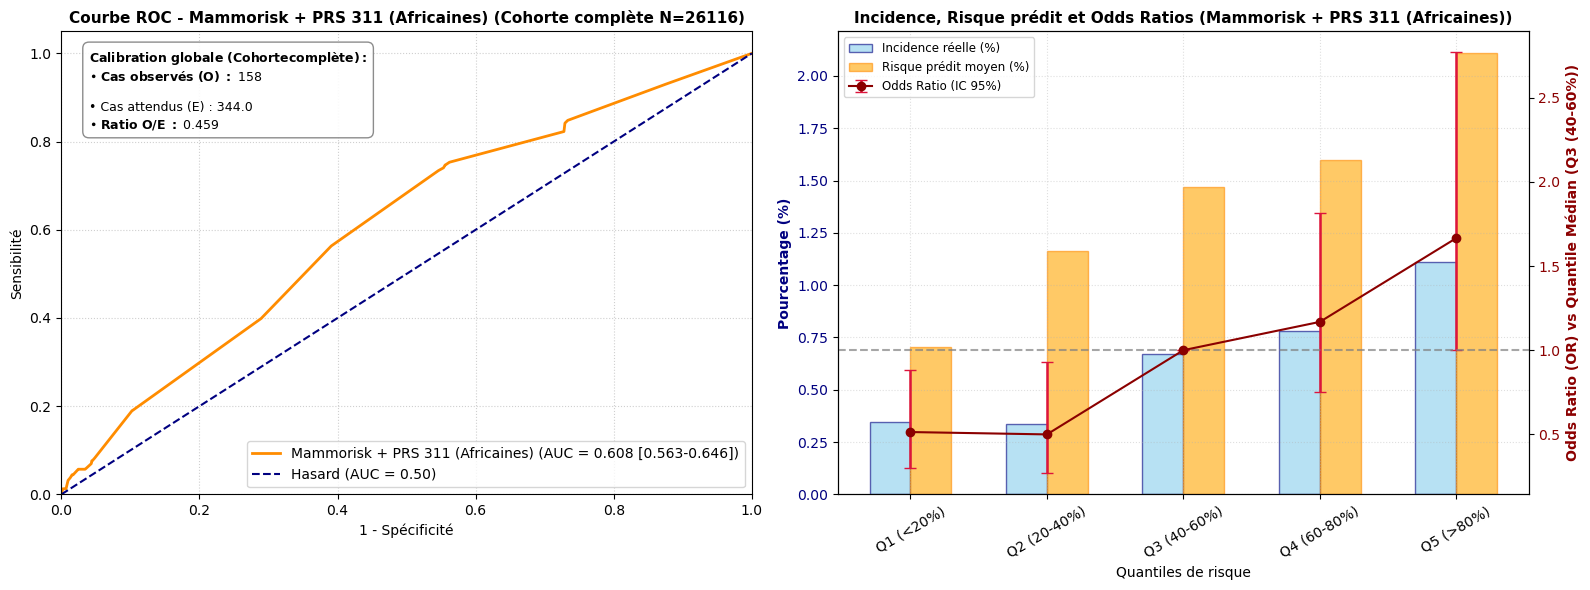

In [81]:
# Évaluation directe sur les ~26 000 femmes d'ascendance africaine (sans découpage)
metrics_afr, df_eval_afr = evaluate_and_plot_model(
    df_data=df_scores,
    score_col="prob_mammorisk_prs311",  # ou score_bcscRisk, prs_311, etc.
    model_name="Mammorisk + PRS 311 (Africaines)",
    target_col="has_bc",
)

In [78]:
df_scores

,person_id,inclusion_date,first_breast_cancer_date,delay_days,age_at_inclusion,has_bc,eur_rye,eas_rye,amr_rye,afr_rye,...,race_us_bcsc,race_us_bcsc_detail,breast_cancer_family_history_first_degree,score_bcscRisk,score_mammorisk,prs_298,prs_305,prs_311,prob_bcsc_prs311,prob_mammorisk_prs311
0,1700611,2019-09-17,NaN,NaN,70.255989,0,0.091868,0.000000,0.0,0.848348,...,2,afr_rye,0,0.016274,0.018173,0.166642,0.229474,0.278546,0.016274,0.018173
1,3095344,2018-07-30,NaN,NaN,57.122519,0,0.149522,0.004112,0.0,0.788366,...,2,afr_rye,0,0.012515,0.016035,-0.276667,-0.173435,-0.221363,0.012515,0.016035
2,5876855,2022-11-03,NaN,NaN,61.385352,0,0.048679,0.000000,0.0,0.886872,...,2,afr_rye,0,0.014353,0.014854,0.220295,0.363527,0.518085,0.014353,0.014854
3,2646710,2019-08-23,NaN,NaN,55.186858,0,0.229365,0.003343,0.0,0.738013,...,2,afr_rye,0,0.012515,0.016035,0.452188,0.517120,0.676192,0.012515,0.016035
4,1197462,2019-11-07,NaN,NaN,55.394935,0,0.079360,0.000000,0.0,0.851251,...,2,afr_rye,0,0.012515,0.016035,0.472726,0.618058,0.625131,0.012515,0.016035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26111,2898673,2018-11-15,NaN,NaN,56.418891,0,0.454550,0.007665,0.0,0.527306,...,2,afr_rye,0,0.012515,0.016035,0.376308,0.142940,0.112607,0.012515,0.016035
26112,4923391,2022-02-07,NaN,NaN,46.650240,0,0.387291,0.000000,0.0,0.524171,...,2,afr_rye,0,0.007422,0.009159,0.233145,0.295977,0.278536,0.007422,0.009159
26113,1257233,2020-01-21,NaN,NaN,62.600958,0,0.272983,0.000000,0.0,0.698327,...,2,afr_rye,1,0.022865,0.022996,0.870686,0.935618,0.943577,0.022865,0.022996
26114,2816958,2019-01-22,NaN,NaN,46.603696,0,0.144538,0.000000,0.0,0.820630,...,2,afr_rye,0,0.007422,0.009159,-0.049625,0.055707,0.060965,0.007422,0.009159
